# 🤖 Assistente Inteligente de Service Desk (Agentic RAG)
**Arquitetura:** LangChain + FAISS + Google Gemini + LangGraph  
**Objetivo:** Realizar a triagem automática de chamados de RH/TI, respondendo dúvidas com base nos documentos PDF de políticas internas (RAG) com citação de fonte, solicitando informações faltantes ou abrindo chamados de exceção.

## 1. Configuração do Ambiente e Conexão com o Google Gemini
Carregamento seguro da chave de API via `.env` e inicialização do modelo `gemini-3.5-flash-lite`.


In [8]:
import os
import re
import time
import pathlib
from pathlib import Path
from typing import Literal, List, Dict, TypedDict, Optional
from pydantic import BaseModel, Field
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_core.messages import SystemMessage, HumanMessage

# Carrega as variáveis do arquivo .env
load_dotenv()
GOOGLE_API_KEY = os.getenv('GOOGLE_API_KEY')

if not GOOGLE_API_KEY:
    raise ValueError("Chave GOOGLE_API_KEY não encontrada no arquivo .env")

# Inicialização do modelo principal
llm = ChatGoogleGenerativeAI(
    model="models/gemini-3.5-flash-lite", 
    api_key=GOOGLE_API_KEY
)

# Teste rápido de conectividade
resp_teste = llm.invoke("conte até 3")
print("Teste de conexão com o Gemini:", resp_teste.content)

Teste de conexão com o Gemini: [{'type': 'text', 'text': '1, 2, 3.', 'extras': {'signature': 'EpYBCpMBAWkUfRPGuGxEZ9NKYGLb2d+K6z6FO19T8sboKMiW4kFDM73WC19QB1h0wylohpCfpaBWULDCLIfBomBgl70doqm0O5tRJgW/VaOOeAN7Ckuv78a8qmAty9B3fliB6JX0mylUkzNQCAmh296BDXEd4JnUCY88GBRhscC80R1fh3O+m1BApFTlhPWEdCvo+ziUTHRU'}}]


## 2. Agente de Triagem com Saída Estruturada (Pydantic)
Utilizamos o `Pydantic` junto ao método `.with_structured_output()` para garantir que o LLM retorne estritamente um objeto estruturado contendo:
- **`decisao`**: `AUTO_RESOLVER`, `PEDIR_INFO` ou `ABRIR_CHAMADO`
- **`urgencia`**: `BAIXA`, `MEDIA` ou `ALTA`
- **`campos_faltantes`**: Lista de informações adicionais necessárias.

In [9]:
TRIAGEM_PROMPT = (
    "Você é um triador de Service Desk para políticas internas da empresa Carraro Desenvolvimento. "
    "Dada a mensagem do usuário, retorne SOMENTE um JSON com:\n"
    "{\n"
    '  "decisao": "AUTO_RESOLVER" | "PEDIR_INFO" | "ABRIR_CHAMADO",\n'
    '  "urgencia": "BAIXA" | "MEDIA" | "ALTA",\n'
    '  "campos_faltantes": ["..."]\n'
    "}\n"
    "Regras:\n"
    '- **AUTO_RESOLVER**: Perguntas claras sobre regras ou procedimentos descritos nas políticas (Ex: "Posso reembolsar a internet do meu home office?", "Como funciona a política de alimentação em viagens?").\n'
    '- **PEDIR_INFO**: Mensagens vagas ou que faltam informações para identificar o tema ou contexto (Ex: "Preciso de ajuda com uma política", "Tenho uma dúvida geral").\n'
    '- **ABRIR_CHAMADO**: Pedidos de exceção, liberação, aprovação ou acesso especial, ou quando o usuário explicitamente pede para abrir um chamado (Ex: "Quero exceção para trabalhar 5 dias remoto.", "Solicito liberação para anexos externos.", "Por favor, abra um chamado para o RH.").'
    "Analise a mensagem e decida a ação mais apropriada."
)

class TriagemOut(BaseModel):
    decisao: Literal["AUTO_RESOLVER", "PEDIR_INFO", "ABRIR_CHAMADO"]
    urgencia: Literal["BAIXA", "MEDIA", "ALTA"]
    campos_faltantes: List[str] = Field(default_factory=list)

llm_triagem = llm

triagem_chain = llm_triagem.with_structured_output(TriagemOut)

def triagem(mensagem: str) -> Dict: 
    saida: TriagemOut = triagem_chain.invoke(
        [
            SystemMessage(content=TRIAGEM_PROMPT),
            HumanMessage(content=mensagem)
        ]
    )
    return saida.model_dump()

# Demonstração isolada da Triagem
testes_triagem = [
    "Posso reembolsar a internet?", 
    "Quero mais 5 dias de trabalho remoto. Como faço?", 
    "Quantas capivaras tem no Rio Pinheiros?"
]

for msg_teste in testes_triagem: 
    print(f"Pergunta: {msg_teste}\n -> Resposta: {triagem(msg_teste)}\n")

Pergunta: Posso reembolsar a internet?
 -> Resposta: {'decisao': 'AUTO_RESOLVER', 'urgencia': 'BAIXA', 'campos_faltantes': []}

Pergunta: Quero mais 5 dias de trabalho remoto. Como faço?
 -> Resposta: {'decisao': 'ABRIR_CHAMADO', 'urgencia': 'MEDIA', 'campos_faltantes': []}

Pergunta: Quantas capivaras tem no Rio Pinheiros?
 -> Resposta: {'decisao': 'AUTO_RESOLVER', 'urgencia': 'BAIXA', 'campos_faltantes': []}



## 3. Ingestão de Documentos PDF e Divisão em Chunks
Leitura automática dos arquivos `.pdf` na pasta `dados/` usando `PyMuPDFLoader` e fragmentação do texto em blocos de 300 caracteres com sobreposição (*overlap*) de 30 caracteres para preservar o contexto semântico.

In [10]:
# Import das bibliotecas de leitura de pdfs
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

docs = []
for n in Path("dados/").glob("*.pdf"):
    try: 
        loader = PyMuPDFLoader(str(n))
        docs.extend(loader.load())
        print(f"Carregado arquivo {n.name} com sucesso!")
    except Exception as e:
        print(f"Erro ao carregar arquivo {n.name}: {e}")

print(f"Total de páginas/documentos carregados: {len(docs)}")

splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=30)
# Divisão do texto em chunks
chunks = splitter.split_documents(docs)

print(f"Total de chunks gerados: {len(chunks)}")
if chunks:
    print("\n--- Exemplo do Primeiro Chunk ---")
    print(chunks[0])

Carregado arquivo Politica_Home_Office_e_Reembolso.pdf com sucesso!
Erro ao carregar arquivo ._Politica_Home_Office_e_Reembolso.pdf: Failed to open file 'dados/._Politica_Home_Office_e_Reembolso.pdf' as type pdf.
Carregado arquivo Politica_Treinamentos_e_Certificacoes.pdf com sucesso!
Carregado arquivo Politica_Seguranca_e_Ferramentas_TI.pdf com sucesso!
Total de páginas/documentos carregados: 8
Total de chunks gerados: 51

--- Exemplo do Primeiro Chunk ---
page_content='CARRARO DESENVOLVIMENTO S.A. NORMATIVA INTERNA DE 
REGIME DE TRABALHO, ELEGIBILIDADE E REEMBOLSO DE 
DESPESAS OPERACIONAIS  
 
Código do Documento: RH-POL-001 
Versão: 4.2 (Vigência: Janeiro a Dezembro de 2026) 
Departamento Responsável: Diretoria de Recursos Humanos e Operações (People & 
Culture)' metadata={'producer': 'macOS Version 27.0.1 (Build 26A434) Quartz PDFContext', 'creator': '', 'creationdate': "D:20261023121409Z00'00'", 'source': 'dados/Politica_Home_Office_e_Reembolso.pdf', 'file_path': 'dados/Politica_H

## 4. Indexação Vetorial (Embeddings + FAISS) e Construção do RAG
Transformação dos chunks de texto em vetores numéricos com o modelo `gemini-embedding-001` e indexação no banco vetorial **FAISS**. Criação da cadeia RAG instruída a não alucinar e formatadores de citação de página.

In [11]:
# IMport das bibliotecas
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import ChatPromptTemplate
import pathlib
import re
from typing import List, Dict

embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001", 
    google_api_key=GOOGLE_API_KEY
)

vectorstore = FAISS.from_documents(chunks, embeddings)

retriever = vectorstore.as_retriever(
    search_type="similarity_score_threshold", 
    search_kwargs={"score_threshold": 0.3, "k": 4}
)

prompt_rag = ChatPromptTemplate.from_messages([
    ("system",
     "Você é um Assistente de Políticas Internas (RH/IT) da empresa Carraro Desenvolvimento. "
     "Responda SOMENTE com base no contexto fornecido. "
     "Se não houver base suficiente, responda apenas 'Não sei'."),
    ("human", "Pergunta: {input}\n\nContexto:\n{context}")
])

# Funções auxiliares para formatação e extração das citações
def _clean_text(s: str) -> str:
    return re.sub(r"\s+", " ", s or "").strip()

def extrair_trecho(texto: str, query: str, janela: int = 240) -> str:
    txt = _clean_text(texto)
    termos = [t.lower() for t in re.findall(r"\w+", query or "") if len(t) >= 4]
    pos = -1
    for t in termos:
        pos = txt.lower().find(t)
        if pos != -1: break
    if pos == -1: pos = 0
    ini, fim = max(0, pos - janela//2), min(len(txt), pos + janela//2)
    return txt[ini:fim]

def formatar_citacoes(docs_rel: List, query: str) -> List[Dict]:
    cites, seen = [], set()
    for d in docs_rel:
        src = pathlib.Path(d.metadata.get("source", "")).name
        page = int(d.metadata.get("page", 0)) + 1
        key = (src, page)
        if key in seen:
            continue
        seen.add(key)
        cites.append({"documento": src, "pagina": page, "trecho": extrair_trecho(d.page_content, query)})
    return cites[:3]

def perguntar_politica_RAG(pergunta: str) -> Dict:
    docs_relacionados = retriever.invoke(pergunta)

    if not docs_relacionados:
        return {"answer": "Não sei.", "citacoes": [], "contexto_encontrado": False}

    # Junta os textos recuperados dos PDFs em uma única string de contexto
    contexto_formatado = "\n\n".join([d.page_content for d in docs_relacionados])

    # Formata o prompt e envia diretamente para o modelo que está ativo
    chain_input = prompt_rag.format_messages(input=pergunta, context=contexto_formatado)
    answer = llm.invoke(chain_input)
    
    # Extração robusta do conteúdo (lê se for string ou lista)
    raw_content = answer.content
    if isinstance(raw_content, list):
        txt = "".join([str(item.get("text", "")) if isinstance(item, dict) else str(item) for item in raw_content]).strip()
    else:
        txt = (raw_content or "").strip()

    if txt.rstrip(".!?") == "Não sei":
        return {"answer": "Não sei.", "citacoes": [], "contexto_encontrado": False}

    return {
        "answer": txt,
        "citacoes": formatar_citacoes(docs_relacionados, pergunta),
        "contexto_encontrado": True
    }

In [12]:
# Teste: 

resultado = perguntar_politica_RAG("Posso reembolsar a internet do meu home office?")
print("Resposta do Assistente:", resultado["answer"])
print("\nCitações encontradas:", resultado["citacoes"])

Resposta do Assistente: Sim, o colaborador pode reembolsar a internet residencial utilizada para o exercício das suas atividades em home office. A Carraro Desenvolvimento concede um auxílio reembolsável mensal de até R$ 120,00 (cento e vinte reais) destinado exclusivamente ao custeio de planos de banda larga fixa residencial. (Planos de telefonia móvel não são elegíveis, salvo em viagens corporativas autorizadas).

Citações encontradas: [{'documento': 'Politica_Home_Office_e_Reembolso.pdf', 'pagina': 2, 'trecho': 'reembolsar a internet residencial utilizada para o exercício das suas atividades em home office. A Carraro Desenvolvimen'}]


## 5. Orquestração do Fluxo de Agentes com LangGraph
Definição do estado do agente (`AgentState`), nós de processamento (`triagem`, `auto_resolver`, `pedir_info`, `abrir_chamado`) e arestas condicionais com mecanismo de *fallback* inteligente caso a busca no RAG não encontre resposta.

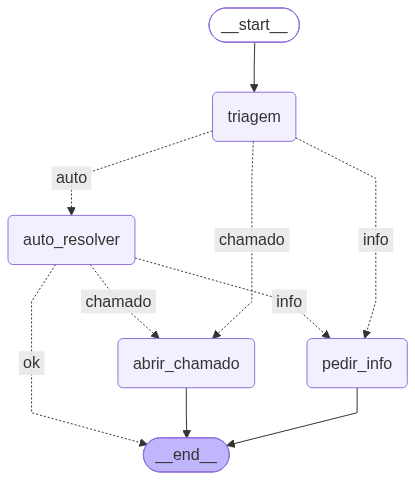

In [13]:
from langgraph.graph import StateGraph, START, END
from IPython.display import display, Image

class AgentState(TypedDict, total=False): 
    pergunta: str
    triagem: dict
    resposta: Optional[str]
    citacoes: List[dict]
    rag_sucesso: bool
    acao_final: str

def node_triagem(state: AgentState) -> AgentState: 
    print("Executando nó de triagem...")
    return {"triagem": triagem(state["pergunta"])}

def node_auto_resolver(state: AgentState) -> AgentState:
    print("Executando nó de auto_resolver...")
    resposta_rag = perguntar_politica_RAG(state["pergunta"])

    update: AgentState = {
        "resposta": resposta_rag["answer"], 
        "citacoes": resposta_rag.get("citacoes", []),
        "rag_sucesso": resposta_rag["contexto_encontrado"], 
    }

    if resposta_rag["contexto_encontrado"]: 
        update["acao_final"] = "AUTO_RESOLVER"

    return update

def node_pedir_info(state: AgentState) -> AgentState:
    print("Executando nó de pedir_info...")
    faltantes = state["triagem"].get("campos_faltantes", [])
    detalhe = ", ".join(faltantes) if faltantes else "Tema e contexto específico"

    return {
        "resposta": f"Para avançar, preciso que detalhe: {detalhe}", 
        "citacoes": [], 
        "acao_final": "PEDIR_INFO"
    }

def node_abrir_chamado(state: AgentState) -> AgentState:
    print("Executando nó de abrir_chamado...")
    triagem_data = state["triagem"]

    return {
        "resposta": f"Abrindo chamado com urgência {triagem_data['urgencia']}. Descrição: {state['pergunta'][:140]}", 
        "citacoes": [], 
        "acao_final": "ABRIR_CHAMADO"
    }

KEYWORDS_ABRIR_TICKET = ["aprovação", "exceção", "liberação", "abrir ticket", "abrir chamado", "acesso especial"]

def decidir_pos_triagem(state: AgentState) -> str:
    print("Decidindo após a triagem...")
    decisao = state["triagem"]["decisao"]
    if decisao == "AUTO_RESOLVER": return "auto"
    if decisao == "PEDIR_INFO": return "info"
    if decisao == "ABRIR_CHAMADO": return "chamado"

def decidir_pos_auto_resolver(state: AgentState) -> str:
    print("Decidindo após o auto_resolver...")
    if state.get("rag_sucesso"):
        print("RAG com sucesso, finalizando o fluxo.")
        return "ok"

    state_da_pergunta = (state["pergunta"] or "").lower()
    if any(k in state_da_pergunta for k in KEYWORDS_ABRIR_TICKET):
        print("RAG falhou, mas foram encontradas keywords de abertura de ticket. Abrindo...")
        return "chamado"

    print("RAG falhou, sem keywords, vou pedir mais informações...")
    return "info" 

# Construção do Grafo
workflow = StateGraph(AgentState)

workflow.add_node("triagem", node_triagem)
workflow.add_node("auto_resolver", node_auto_resolver)
workflow.add_node("pedir_info", node_pedir_info)
workflow.add_node("abrir_chamado", node_abrir_chamado)

workflow.add_edge(START, "triagem")
workflow.add_conditional_edges("triagem", decidir_pos_triagem, {
    "auto": "auto_resolver",
    "info": "pedir_info",
    "chamado": "abrir_chamado"
})
workflow.add_conditional_edges("auto_resolver", decidir_pos_auto_resolver, {
    "info": "pedir_info",
    "chamado": "abrir_chamado",
    "ok": END
})
workflow.add_edge("pedir_info", END)
workflow.add_edge("abrir_chamado", END)

grafo = workflow.compile()

# Exibição visual da arquitetura do Grafo no Notebook
try:
    graph_bytes = grafo.get_graph().draw_mermaid_png()
    display(Image(graph_bytes))
except Exception as e:
    print("Grafo compilado com sucesso!")

## 6. Bateria de Testes e Demonstração Completa
Execução ponta a ponta do assistente avaliando perguntas sobre políticas existentes nos PDFs, solicitações de exceção e perguntas fora de escopo (prevenção de alucinação).

In [14]:
testes_finais = [
    "Posso reembolsar a internet?",
    "Quero mais 5 dias de trabalho remoto. Como faço?",
    "Posso reembolsar cursos ou treinamentos da Alura?",
    "É possível reembolsar certificações do Google Cloud?",
    "Posso obter o Google Gemini de graça?",
    "Qual é a palavra-chave da aula de hoje?",
    "Quantas capivaras tem no Rio Pinheiros?"
]

for idx, msg_test in enumerate(testes_finais, 1):
    print(f"=== TESTE {idx} ===")
    resposta_final = grafo.invoke({"pergunta": msg_test})

    triag = resposta_final.get("triagem", {})
    print(f"PERGUNTA: {msg_test}")
    print(f"DECISÃO: {triag.get('decisao')} | URGÊNCIA: {triag.get('urgencia')} | AÇÃO FINAL: {resposta_final.get('acao_final')}")
    print(f"RESPOSTA: {resposta_final.get('resposta')}")
    
    if resposta_final.get("citacoes"):
        print("CITAÇÕES:")
        for citacao in resposta_final.get("citacoes"):
            print(f" - Doc: {citacao['documento']} (Pág. {citacao['pagina']})")
            print(f"   Trecho: {citacao['trecho']}")

    print("-" * 50)
    # Pausa rápida entre as chamadas
    time.sleep(5)

=== TESTE 1 ===
Executando nó de triagem...
Decidindo após a triagem...
Executando nó de auto_resolver...
Decidindo após o auto_resolver...
RAG com sucesso, finalizando o fluxo.
PERGUNTA: Posso reembolsar a internet?
DECISÃO: AUTO_RESOLVER | URGÊNCIA: BAIXA | AÇÃO FINAL: AUTO_RESOLVER
RESPOSTA: Sim, o colaborador pode reembolsar a internet residencial utilizada para o exercício das suas atividades em home office, conforme o custeio de planos de banda larga fixa residencial (planos de telefonia móvel não são elegíveis, salvo em viagens corporativas autorizadas). A Carraro Desenvolvimento concede um auxílio reembolsável mensal de até R$ 120,00 (cento e vinte reais) para essa finalidade.
CITAÇÕES:
 - Doc: Politica_Home_Office_e_Reembolso.pdf (Pág. 2)
   Trecho: 4G/5G) não são elegíveis neste benefício, salvo em viagens corporativas autorizadas. 4.2. Como Solicitar o Reembolso da Internet: Para receber o reembolso mensal
--------------------------------------------------
=== TESTE 2 ===
Ex

## 7. Consulta Interativa
Execute esta célula para enviar uma pergunta personalizada ao assistente.

In [15]:
pergunta_usuario = input("Digite sua pergunta para o Assistente: ").strip()

if pergunta_usuario:
    resposta_final = grafo.invoke({"pergunta": pergunta_usuario})
    triag = resposta_final.get("triagem", {})

    print(f"\nPERGUNTA: {pergunta_usuario}")
    print(f"DECISÃO: {triag.get('decisao')} | URGÊNCIA: {triag.get('urgencia')} | AÇÃO FINAL: {resposta_final.get('acao_final')}")
    print(f"RESPOSTA: {resposta_final.get('resposta')}")

    if resposta_final.get("citacoes"):
        print("\nCITAÇÕES:")
        for citacao in resposta_final.get("citacoes"):
            print(f" - Doc: {citacao['documento']} (Pág. {citacao['pagina']})")
            print(f"   Trecho: {citacao['trecho']}")
else:
    print("Nenhuma pergunta informada.")

Executando nó de triagem...
Decidindo após a triagem...
Executando nó de auto_resolver...
Decidindo após o auto_resolver...
RAG falhou, sem keywords, vou pedir mais informações...
Executando nó de pedir_info...

PERGUNTA: Temos politicas sobre animais no trabalho?
DECISÃO: AUTO_RESOLVER | URGÊNCIA: BAIXA | AÇÃO FINAL: PEDIR_INFO
RESPOSTA: Para avançar, preciso que detalhe: Tema e contexto específico
